In [4]:
!pip install ultralytics codecarbon -q

[codecarbon INFO @ 20:34:18] Energy consumed for RAM : 0.000998 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 20:34:18] Energy consumed for all GPUs : 0.002578 kWh. Total GPU Power : 26.339444809098918 W
[codecarbon INFO @ 20:34:18] Delta energy consumed for CPU with cpu_load : 0.000001 kWh, power : 1.0351891892000002 W
[codecarbon INFO @ 20:34:18] Energy consumed for All CPU : 0.000105 kWh
[codecarbon INFO @ 20:34:18] 0.003681 kWh of electricity and 0.000000 L of water were used since the beginning.


In [5]:
!git clone https://github.com/PovMiki/garbage-yolo.git

Cloning into 'garbage-yolo'...
remote: Enumerating objects: 24775, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (21/21), done.


[codecarbon INFO @ 20:34:23] Energy consumed for RAM : 0.001012 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 20:34:23] Energy consumed for all GPUs : 0.002614 kWh. Total GPU Power : 26.36153419751057 W
[codecarbon INFO @ 20:34:23] Delta energy consumed for CPU with cpu_load : 0.000002 kWh, power : 1.7386512188000003 W
[codecarbon INFO @ 20:34:23] Energy consumed for All CPU : 0.000107 kWh
[codecarbon INFO @ 20:34:23] 0.003733 kWh of electricity and 0.000000 L of water were used since the beginning.


[codecarbon INFO @ 20:34:28] Energy consumed for RAM : 0.001026 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 20:34:28] Energy consumed for all GPUs : 0.002651 kWh. Total GPU Power : 26.30755629319657 W
[codecarbon INFO @ 20:34:28] Delta energy consumed for CPU with cpu_load : 0.000010 kWh, power : 7.094574389600001 W
[codecarbon INFO @ 20:34:28] Energy consumed for All CPU : 0.000117 kWh
[codecarbon INFO @ 20:34:28] 0.003794 kWh of electricity and 0.000000 L of water were used since the beginning.


[codecarbon INFO @ 20:34:33] Energy consumed for RAM : 0.001040 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 20:34:33] Energy consumed for all GPUs : 0.002687 kWh. Total GPU Power : 26.31117030581966 W
[codecarbon INFO @ 20:34:33] Delta energy consumed for CPU with cpu_load : 0.000011 kWh, power : 7.7277889748 W
[codecarbon INFO @ 20:34:33] Energy consumed for All CPU : 0.000128 kWh
[codecarbon INFO @ 20:34:33] 0.003855 kWh of electricity and 0.000000 L of water were used since the beginning.


[codecarbon INFO @ 20:34:38] Energy consumed for RAM : 0.001054 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 20:34:38] Energy consumed for all GPUs : 0.002724 kWh. Total GPU Power : 26.456893838513423 W
[codecarbon INFO @ 20:34:38] Delta energy consumed for CPU with cpu_load : 0.000003 kWh, power : 2.390878568 W
[codecarbon INFO @ 20:34:38] Energy consumed for All CPU : 0.000131 kWh
[codecarbon INFO @ 20:34:38] 0.003909 kWh of electricity and 0.000000 L of water were used since the beginning.


[codecarbon INFO @ 20:34:43] Energy consumed for RAM : 0.001068 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 20:34:43] Energy consumed for all GPUs : 0.002761 kWh. Total GPU Power : 26.416870286645658 W
[codecarbon INFO @ 20:34:43] Delta energy consumed for CPU with cpu_load : 0.000002 kWh, power : 1.224906206 W
[codecarbon INFO @ 20:34:43] Energy consumed for All CPU : 0.000133 kWh
[codecarbon INFO @ 20:34:43] 0.003961 kWh of electricity and 0.000000 L of water were used since the beginning.


remote: Total 24775 (delta 5), reused 18 (delta 2), pack-reused 24752 (from 1)
Receiving objects: 100% (24775/24775), 489.16 MiB | 20.73 MiB/s, done.
Resolving deltas: 100% (2460/2460), done.


[codecarbon INFO @ 20:34:48] Energy consumed for RAM : 0.001081 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 20:34:48] Energy consumed for all GPUs : 0.002796 kWh. Total GPU Power : 25.874042402329703 W
[codecarbon INFO @ 20:34:48] Delta energy consumed for CPU with cpu_load : 0.000002 kWh, power : 1.4055206192 W
[codecarbon INFO @ 20:34:48] Energy consumed for All CPU : 0.000135 kWh
[codecarbon INFO @ 20:34:48] 0.004012 kWh of electricity and 0.000000 L of water were used since the beginning.


Updating files: 100% (20269/20269), done.


In [6]:
import torch

if torch.cuda.is_available():
    print(f"GPU jest dostępne: {torch.cuda.get_device_name(0)}")
else:
    print("Brak GPU! Zmień środowisko wykonawcze w Colabie (Runtime -> Change runtime type -> T4 GPU)")

GPU jest dostępne: Tesla T4


In [7]:
import yaml

# Ścieżka do pobranego z GitHuba pliku data.yaml
yaml_file = '/content/garbage-yolo/dataset_clean/data.yaml'

# Wczytanie obecnej zawartości
with open(yaml_file, 'r') as f:
    data = yaml.safe_load(f)

# Podmiana ścieżki bazowej na folder w Colabie
data['path'] = '/content/garbage-yolo/dataset_clean'

# Zapisanie zmian
with open(yaml_file, 'w') as f:
    yaml.dump(data, f, sort_keys=False)

print("Zaktualizowano ścieżkę w data.yaml dla Google Colab!")

Zaktualizowano ścieżkę w data.yaml dla Google Colab!


In [8]:
from ultralytics import YOLO
from codecarbon import EmissionsTracker

DATA_YAML_PATH = '/content/garbage-yolo/dataset_clean/data.yaml'

tracker = EmissionsTracker(project_name="YOLO11_Nano_Baseline", measure_power_secs=5)
model = YOLO('yolo11n.pt')

print("Rozpoczynam logowanie zużycia energii i trening...")
tracker.start()

results = model.train(
    data=DATA_YAML_PATH,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,                # Upewnij się, że masz włączone GPU (T4)
    workers=2,
    project="Trash_Detection",
    name="Baseline_Model",

    # WYŁĄCZENIE AUGMENTACJI
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=0.0, translate=0.0,
    scale=0.0, shear=0.0, perspective=0.0, flipud=0.0, fliplr=0.0,
    bgr=0.0, mosaic=0.0, mixup=0.0, copy_paste=0.0, erasing=0.0
)

emissions: float = tracker.stop()

print(f"\n--- RAPORT ŚRODOWISKOWY ---")
print(f"Trening modelu wygenerował przybliżoną emisję: {emissions:.6f} kg CO2.")

[codecarbon WARNING @ 20:34:52] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 20:34:52] Emissions data (if any) will be saved to file /content/emissions.csv
[codecarbon INFO @ 20:34:52] Monitoring GPUs with indices: [0] out of 1 total GPUs
[codecarbon INFO @ 20:34:52] >>> Tracker's metadata:
[codecarbon INFO @ 20:34:52]   Platform system: Linux-6.6.122+-x86_64-with-glibc2.39
[codecarbon INFO @ 20:34:52]   Python version: 3.13.15
[codecarbon INFO @ 20:34:52]   CodeCarbon version: 3.3.1
[codecarbon INFO @ 20:34:52]   Available RAM : 12.671 GB
[codecarbon INFO @ 20:34:52]   CPU count: 2 thread(s) in 1 physical CPU(s)
[codecarbon INFO @ 20:34:52]   CPU model: Intel(R) Xeon(R) CPU @ 2.00GHz
[codecarbon INFO @ 20:34:52]   GPU count: 1
[codecarbon INFO @ 20:34:52]   GPU model: 1 x Tesla T4
[codecarbon INFO @ 20:34:52] Energy consumed for RAM : 0.000000 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 20:34:52] Monitoring GPUs with indices: [0] out of 1 tot

Rozpoczynam logowanie zużycia energii i trening...
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/garbage-yolo/dataset_clean/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.0, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0,

[codecarbon INFO @ 20:34:53] Energy consumed for RAM : 0.001095 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 20:34:53] Energy consumed for all GPUs : 0.002833 kWh. Total GPU Power : 26.43005230391798 W
[codecarbon INFO @ 20:34:53] Delta energy consumed for CPU with cpu_load : 0.000002 kWh, power : 1.7191256636000003 W
[codecarbon INFO @ 20:34:53] Energy consumed for All CPU : 0.000137 kWh
[codecarbon INFO @ 20:34:53] 0.004065 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 20:34:53] 0.003809 g.CO2eq/s mean an estimation of 120.12381455819558 kg.CO2eq/year


YOLO11n summary: 181 layers, 2,591,010 parameters, 2,590,994 gradients, 6.5 GFLOPs

Transferred 493/499 items from pretrained weights
Freezing layer 'model.23.dfl.conv.weight'
AMP: running Automatic Mixed Precision (AMP) checks...
AMP: downloading yolo26n.pt for AMP checks (one-time, not used for training)...


[codecarbon INFO @ 20:34:57] Energy consumed for RAM : 0.000014 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 20:34:57] Energy consumed for all GPUs : 0.000037 kWh. Total GPU Power : 26.402360152407073 W
[codecarbon INFO @ 20:34:57] Delta energy consumed for CPU with cpu_load : 0.000008 kWh, power : 6.014423556800001 W
[codecarbon INFO @ 20:34:57] Energy consumed for All CPU : 0.000008 kWh
[codecarbon INFO @ 20:34:57] 0.000059 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 20:34:58] Energy consumed for RAM : 0.001109 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 20:34:58] Energy consumed for all GPUs : 0.002870 kWh. Total GPU Power : 26.407201973434514 W
[codecarbon INFO @ 20:34:58] Delta energy consumed for CPU with cpu_load : 0.000009 kWh, power : 6.6528916076 W
[codecarbon INFO @ 20:34:58] Energy consumed for All CPU : 0.000146 kWh
[codecarbon INFO @ 20:34:58] 0.004125 kWh of electricity and 0.000000 L of water were used since the beginning.


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 2.1it/s 15.0s


[codecarbon INFO @ 21:10:58] Energy consumed for RAM : 0.005977 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 21:10:58] Energy consumed for all GPUs : 0.036715 kWh. Total GPU Power : 46.32805889378216 W
[codecarbon INFO @ 21:10:58] Delta energy consumed for CPU with cpu_load : 0.000010 kWh, power : 7.3963416332000005 W
[codecarbon INFO @ 21:10:58] Energy consumed for All CPU : 0.004673 kWh
[codecarbon INFO @ 21:10:58] 0.047365 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 21:10:59] Energy consumed for RAM : 0.007074 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 21:10:59] Energy consumed for all GPUs : 0.039552 kWh. Total GPU Power : 44.4342973064423 W
[codecarbon INFO @ 21:10:59] Delta energy consumed for CPU with cpu_load : 0.000009 kWh, power : 6.2899553516 W
[codecarbon INFO @ 21:10:59] Energy consumed for All CPU : 0.004829 kWh
[codecarbon INFO @ 21:10:59] 0.051455 kWh of electricity and 0.000000 L of water were used since the beginning.


                   all       1008       7284      0.607       0.46      0.481      0.324
         BIODEGRADABLE        171       4450      0.644      0.385      0.432      0.208
             CARDBOARD        172        451      0.414      0.532      0.478       0.34
                 GLASS        177        432      0.789       0.62      0.685      0.501
                 METAL        233        789       0.57      0.501      0.507      0.337
                 PAPER        168        347      0.626      0.372      0.393      0.306
               PLASTIC        179        815      0.601      0.348      0.394      0.255
Speed: 0.5ms preprocess, 4.4ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /content/runs/detect/Trash_Detection/Baseline_Model-2


[codecarbon INFO @ 21:11:03] Energy consumed for RAM : 0.005990 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 21:11:03] Energy consumed for all GPUs : 0.036756 kWh. Total GPU Power : 31.454806303038186 W
[codecarbon INFO @ 21:11:03] Delta energy consumed for CPU with cpu_load : 0.000006 kWh, power : 4.280027066000001 W
[codecarbon INFO @ 21:11:03] Energy consumed for All CPU : 0.004678 kWh
[codecarbon INFO @ 21:11:03] 0.047424 kWh of electricity and 0.000000 L of water were used since the beginning.



--- RAPORT ŚRODOWISKOWY ---
Trening modelu wygenerował przybliżoną emisję: 0.016562 kg CO2.


In [9]:
import pandas as pd

try:
    df_emissions = pd.read_csv('../stare/wyniki/emissions.csv')
    display(df_emissions[['timestamp', 'project_name', 'duration', 'emissions', 'energy_consumed', 'cpu_energy', 'gpu_energy']])
except FileNotFoundError:
    print("Nie znaleziono pliku emissions.csv")

,timestamp,project_name,duration,emissions,energy_consumed,cpu_energy,gpu_energy
0,2026-10-15T21:11:03,YOLO11_Nano_Baseline,2170.846505,0.016562,0.047424,0.004678,0.036756


📊 --- WIZUALNA ANALIZA WYNIKÓW TRENINGU BASELINE --- 📊

1. Krzywe uczenia (Loss) oraz metryki (Precision, Recall, mAP):


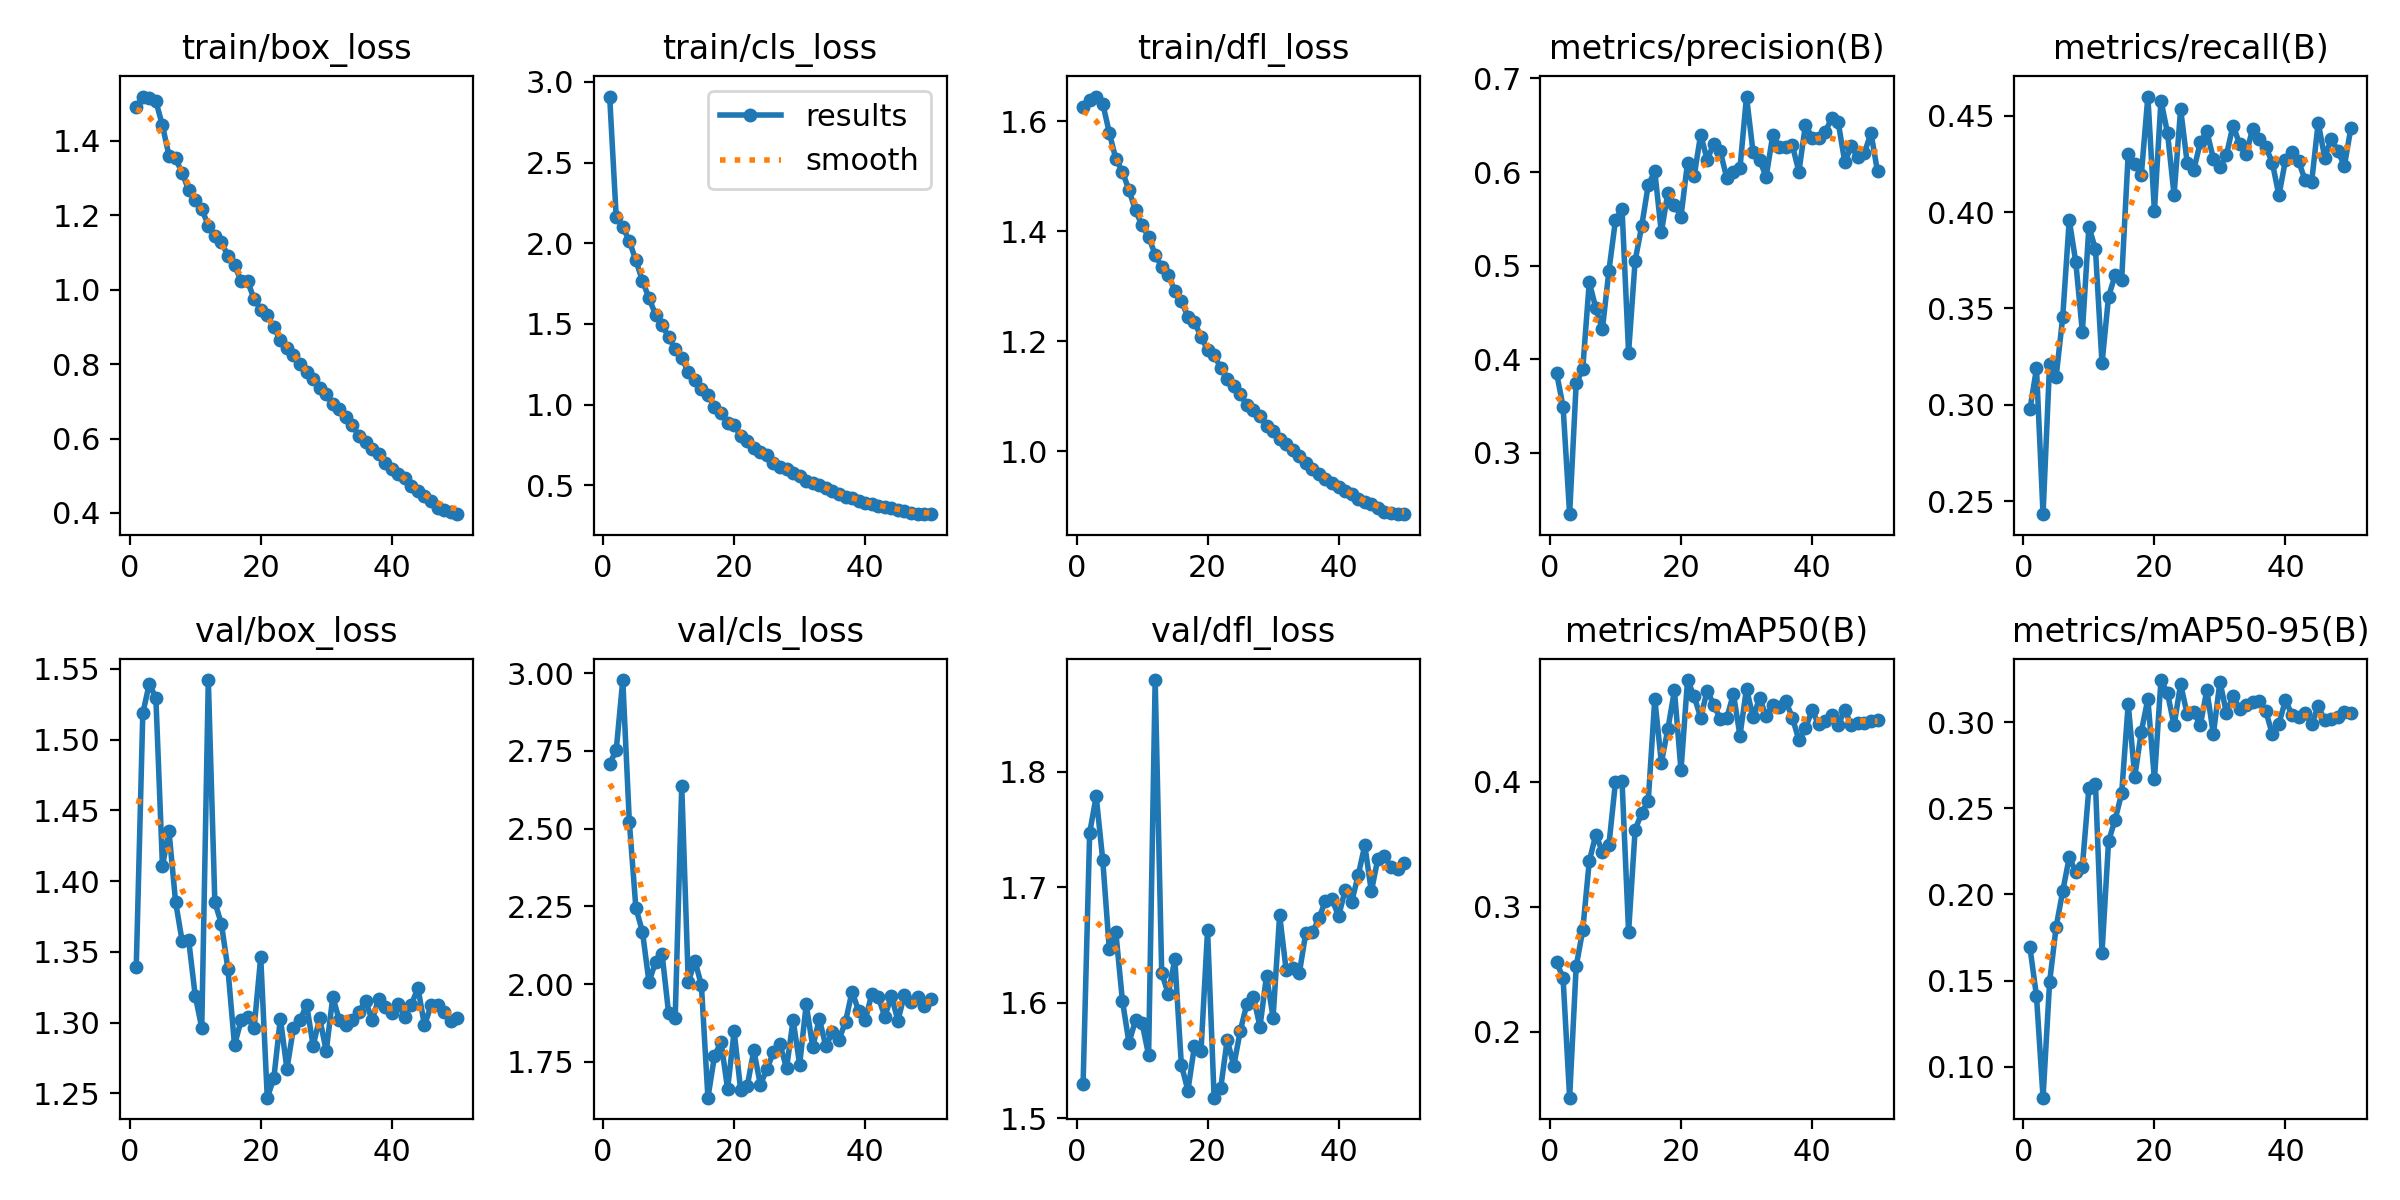


2. Znormalizowana Macierz Pomyłek (pokazuje z czym model myli konkretne klasy):


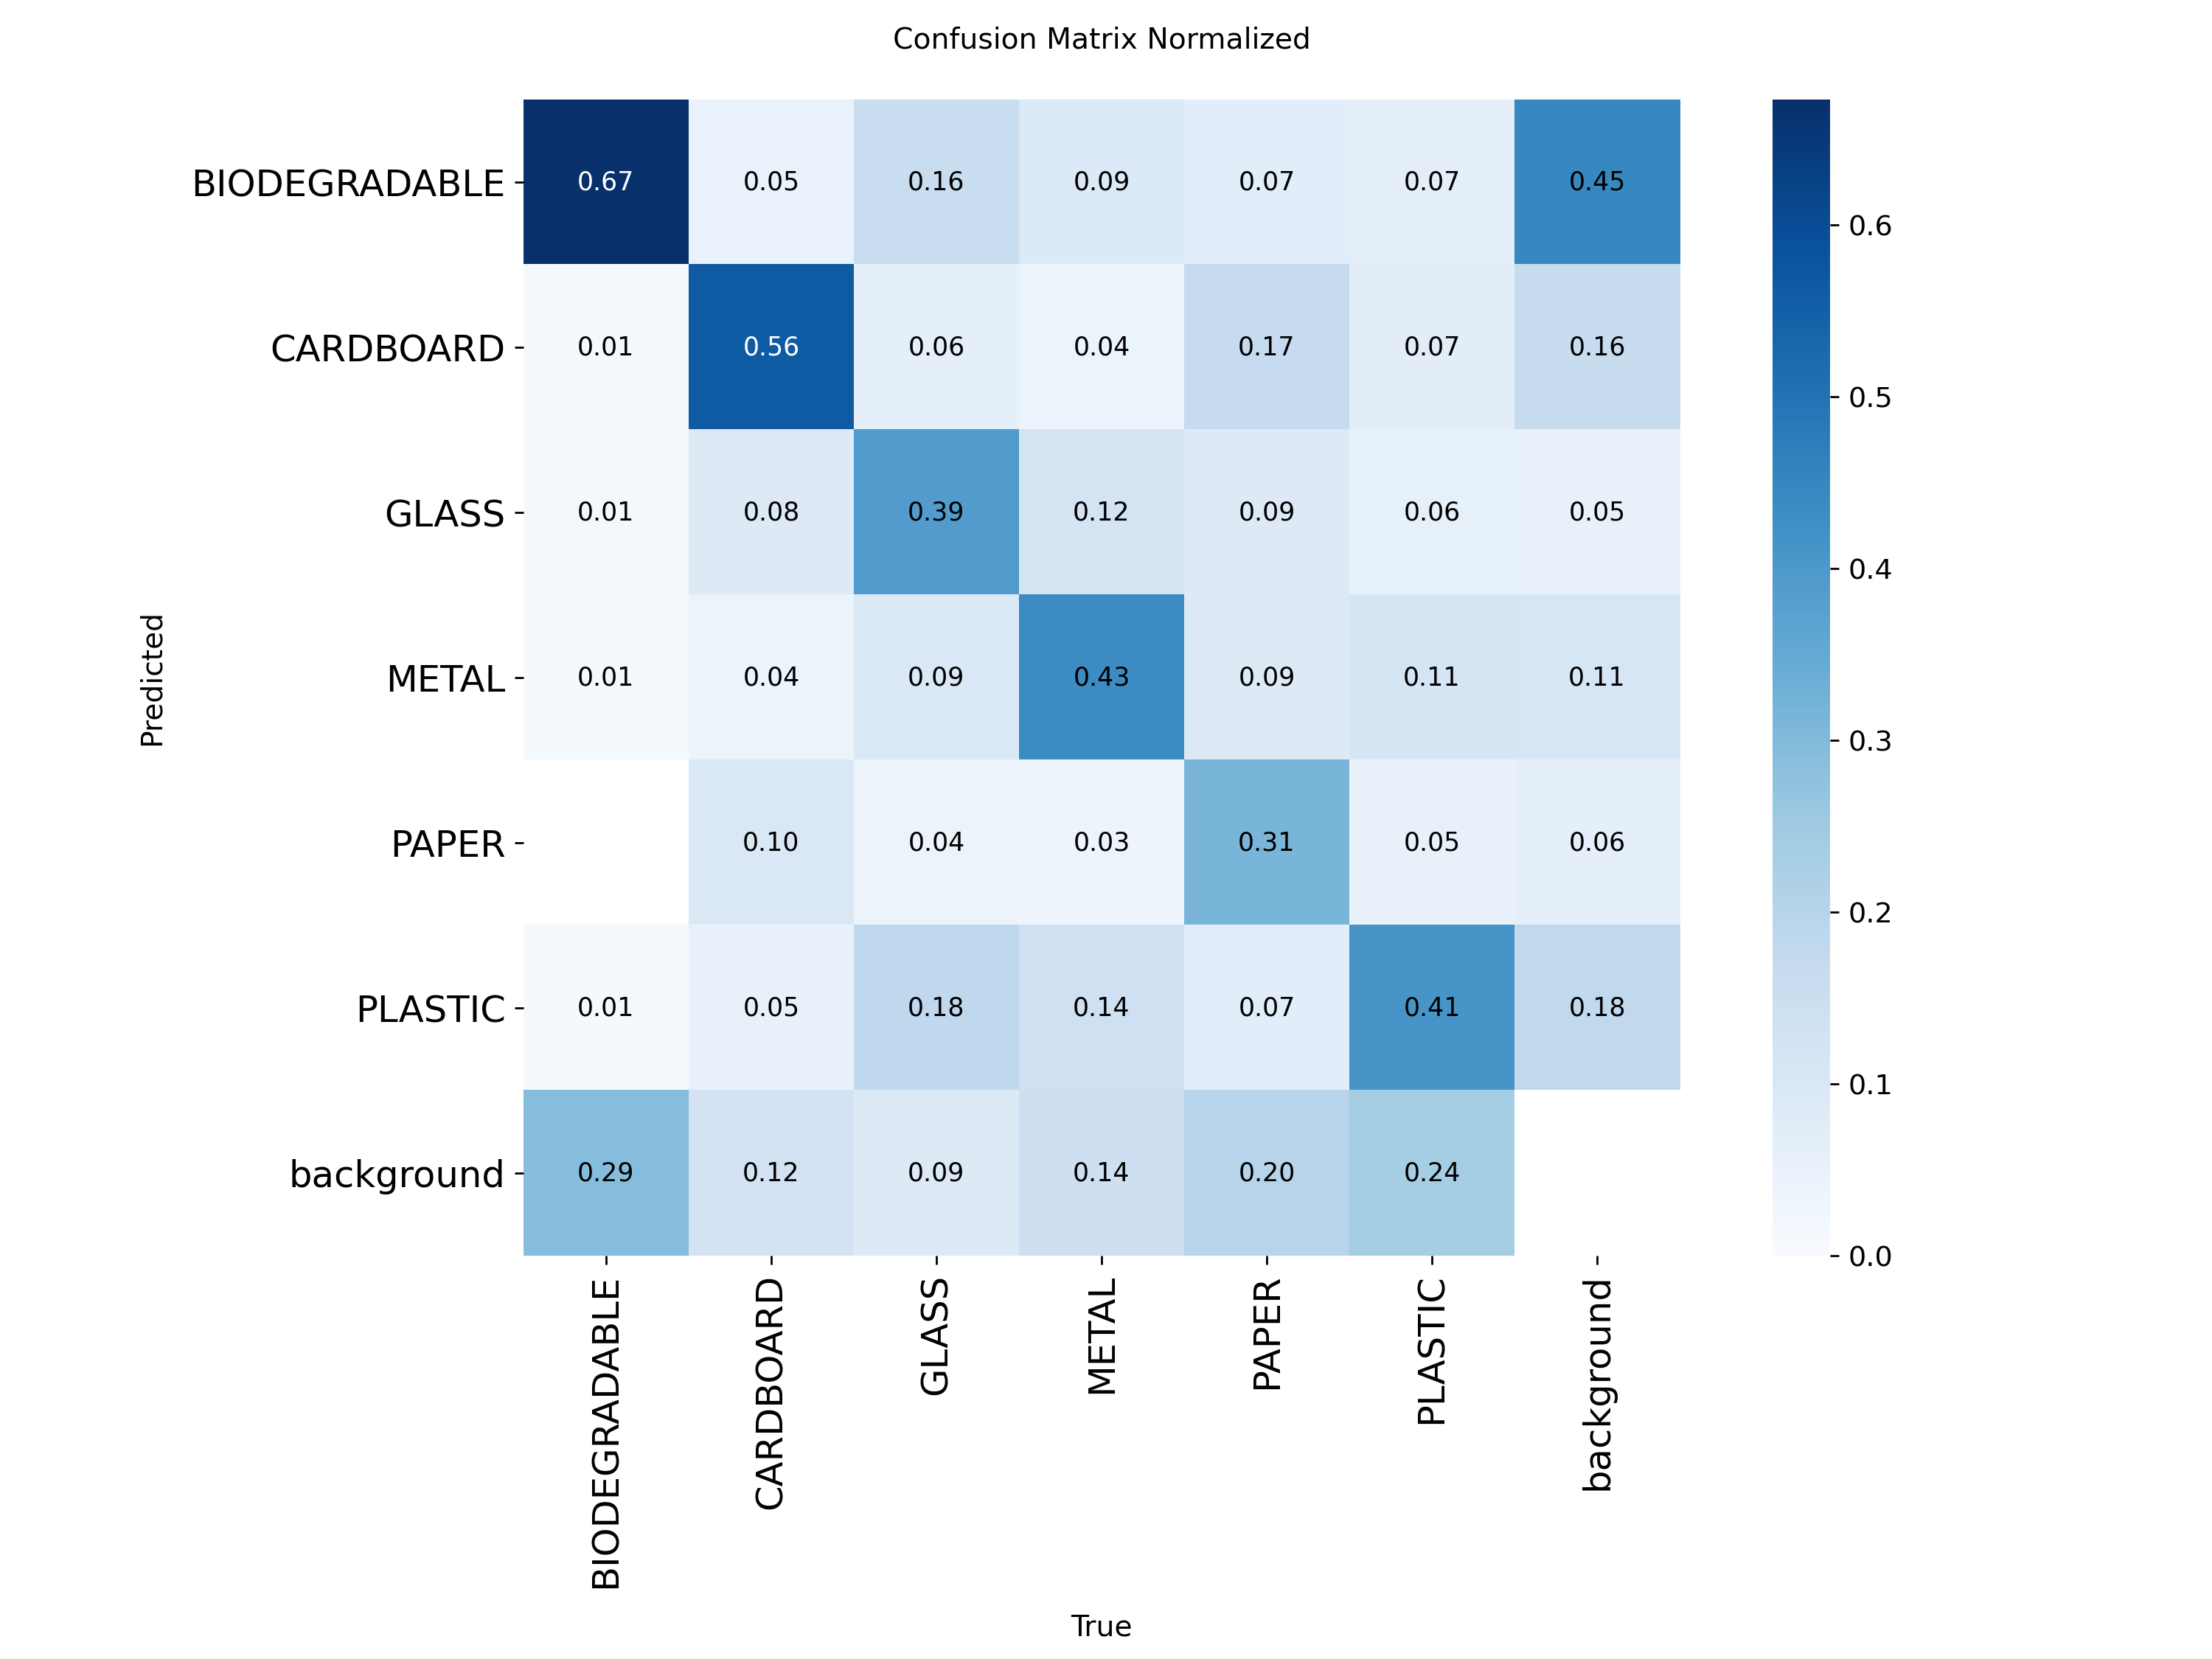

In [11]:
import os
from IPython.display import Image, display
import pandas as pd

# Ścieżka do folderu z wynikami (zdefiniowana w argumentach model.train)
RESULTS_DIR = "Trash_Detection/Baseline_Model"

print("📊 --- WIZUALNA ANALIZA WYNIKÓW TRENINGU BASELINE --- 📊")

# 1. Wyświetlenie wykresów z procesu uczenia (strata i metryki mAP50, mAP50-95 per epoka)
results_img = os.path.join(RESULTS_DIR, "/content/runs/detect/Trash_Detection/Baseline_Model-2/results.png")
if os.path.exists(results_img):
    print("\n1. Krzywe uczenia (Loss) oraz metryki (Precision, Recall, mAP):")
    display(Image(filename=results_img, width=1000))
else:
    print("\nBrak pliku results.png.")

# 2. Wyświetlenie Znormalizowanej Macierzy Pomyłek (Confusion Matrix)
cm_img = os.path.join(RESULTS_DIR, "/content/runs/detect/Trash_Detection/Baseline_Model-2/confusion_matrix_normalized.png")
if os.path.exists(cm_img):
    print("\n2. Znormalizowana Macierz Pomyłek (pokazuje z czym model myli konkretne klasy):")
    display(Image(filename=cm_img, width=800))
else:
    print("\nBrak pliku macierzy pomyłek.")

# 3. Wyświetlenie krzywej PR (Precision-Recall)
pr_curve = os.path.join(RESULTS_DIR, "PR_curve.png")
if os.path.exists(pr_curve):
    print("\n3. Krzywa Precision-Recall (im bliżej prawego górnego rogu, tym lepiej):")
    display(Image(filename=pr_curve, width=800))

# 4. Wyświetlenie surowych wartości metryk z ostatniej epoki z pliku results.csv
results_csv = os.path.join(RESULTS_DIR, "results.csv")
if os.path.exists(results_csv):
    print("\n4. Surowe wyniki z ostatniej epoki (najlepsze/najbardziej aktualne wagi):")
    df_results = pd.read_csv(results_csv)
    # Usuwamy ewentualne spacje w nazwach kolumn wygenerowanych przez YOLO
    df_results.columns = df_results.columns.str.strip()

    # Wyciągamy ostatni wiersz i interesujące nas kolumny
    last_epoch = df_results.iloc[-1]
    metrics = {
        "Epoka": int(last_epoch['epoch']),
        "Precyzja (Precision)": round(last_epoch['metrics/precision(B)'], 4),
        "Czułość (Recall)": round(last_epoch['metrics/recall(B)'], 4),
        "mAP50": round(last_epoch['metrics/mAP50(B)'], 4),
        "mAP50-95": round(last_epoch['metrics/mAP50-95(B)'], 4)
    }

    df_metrics = pd.DataFrame([metrics])
    display(df_metrics.style.hide(axis="index"))

In [13]:
# 1. Pakowanie wybranych folderów i plików do archiwum ZIP
!zip -r wyniki_treningu.zip runs weights emissions.csv data.yaml yolo11n.pt

# 2. Automatyczne wywołanie pobierania utworzonego pliku
from google.colab import files
files.download('wyniki_treningu.zip')

  adding: runs/ (stored 0%)
  adding: runs/detect/ (stored 0%)
  adding: runs/detect/Trash_Detection/ (stored 0%)
  adding: runs/detect/Trash_Detection/Baseline_Model-2/ (stored 0%)
  adding: runs/detect/Trash_Detection/Baseline_Model-2/results.csv (deflated 60%)
  adding: runs/detect/Trash_Detection/Baseline_Model-2/val_batch1_pred.jpg (deflated 7%)
  adding: runs/detect/Trash_Detection/Baseline_Model-2/confusion_matrix_normalized.png (deflated 17%)
  adding: runs/detect/Trash_Detection/Baseline_Model-2/train_batch8840.jpg (deflated 7%)
  adding: runs/detect/Trash_Detection/Baseline_Model-2/BoxP_curve.png (deflated 7%)
  adding: runs/detect/Trash_Detection/Baseline_Model-2/BoxPR_curve.png (deflated 7%)
  adding: runs/detect/Trash_Detection/Baseline_Model-2/val_batch2_pred.jpg (deflated 4%)
  adding: runs/detect/Trash_Detection/Baseline_Model-2/results.png (deflated 6%)
  adding: runs/detect/Trash_Detection/Baseline_Model-2/train_batch0.jpg (deflated 3%)
  adding: runs/detect/Trash_Det

[codecarbon INFO @ 21:22:39] Energy consumed for RAM : 0.009015 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 21:22:39] Energy consumed for all GPUs : 0.044895 kWh. Total GPU Power : 26.730660607610602 W
[codecarbon INFO @ 21:22:39] Delta energy consumed for CPU with cpu_load : 0.000004 kWh, power : 2.7528636764 W
[codecarbon INFO @ 21:22:39] Energy consumed for All CPU : 0.005000 kWh
[codecarbon INFO @ 21:22:39] 0.058911 kWh of electricity and 0.000000 L of water were used since the beginning.


 (deflated 11%)
  adding: emissions.csv (deflated 40%)
  adding: data.yaml (deflated 84%)
  adding: yolo11n.pt (deflated 11%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>